# **Etsy Challenge**

---
# Step 1: Setup
Setting up imports, downloads, etc.

## 1. Imports

In [81]:
# Takes long to install, best to install in the terminal

# !pip install cleanvision fiftyone
# !pip uninstall onnxruntime onnxruntime-gpu
# !pip install onnxruntime-gpu
# !pip install rembg[gpu]

In [82]:

# GENERAL, DATA, PLOTS, IMAGES & UTILS
import setuptools
from tqdm import tqdm
import time
from IPython.display import clear_output
import hashlib
import pandas as pd  
import numpy as np
import kagglehub  
import cv2 
import urllib3
import os  
import shutil
import zipfile
from pathlib import Path 
from collections import Counter
import gc

# Plots & Images
import seaborn as sns  
from matplotlib import pyplot as plt  
import plotly.express as px  
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import PIL
from PIL import ImageFile, Image
from skimage import io, data, exposure, img_as_ubyte
from skimage.color import rgb2gray
from skimage.filters import threshold_sauvola, gaussian
from skimage.feature import hog, graycomatrix, graycoprops

# Analysis & Data Manipulation
import shap
import shap.maskers
from cleanvision import Imagelab 
import fiftyone as fo 
import fiftyone.zoo as foz 
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN 
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

ImageFile.LOAD_TRUNCATED_IMAGES = True



# HEAVY AI (MUST LOAD FIRST)
# Let PyTorch and TensorFlow grab their own native DLLs before we mess with the paths!
from fastcore.all import *
from fastai.vision.all import * 
from fastai.callback.progress import ProgressCallback  
from fastprogress.fastprogress import ConsoleMasterBar, ConsoleProgressBar
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
from torchvision.models import resnet50 
import timm

from tensorflow import keras
from keras.applications.resnet50 import ResNet50, preprocess_input

master_bar, progress_bar = ConsoleMasterBar, ConsoleProgressBar  
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") 



# THE ONNX VIP PASS
site_pkg = r"c:\Users\Danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages"
nvidia_base = os.path.join(site_pkg, "nvidia")
trusted_folders = [os.getcwd()] # Keeps zlibwapi.dll active!

if os.path.exists(nvidia_base):
    for folder in os.listdir(nvidia_base):
        bin_path = os.path.join(nvidia_base, folder, "bin")
        if os.path.exists(bin_path):
            trusted_folders.append(bin_path)

for folder in trusted_folders:
    if hasattr(os, 'add_dll_directory'):
        os.add_dll_directory(folder)
    os.environ["PATH"] = folder + os.pathsep + os.environ.get("PATH", "")


# ONNX & REMBG (LOADS LAST)
# Now that the paths are set, ONNX will find the CUDA 12 files for your RTX 5070
import onnxruntime
import onnxruntime as rt
from rembg import remove, new_session 

print("✅ All imports completely successfully! Environment is stable.")

✅ All imports completely successfully! Environment is stable.


## 2. Setting paths, Extracting Images + Downloading new datasets...

In [83]:
#########################
# Setting paths
#########################

# General paths
challenge_dir = "data/google_drive"
zip_path = os.path.join(challenge_dir, "genai_image_challenge.zip")
created_dir = "data/other_datasets/created_datasets"
available_dir = "data/other_datasets/available_datasets"
other_dir = "data/other_datasets"
etsy_dir = f"{challenge_dir}/final_test_images/images_final_sample/images_final_sample"





#########################
# Unzip etsy dataset
#########################

# Error handler (for zip path)
if os.path.exists(zip_path):
    print("Path exists!\n")
else:
    raise Exception(f"Path not found.")

# Unzip etsy dataset for final test
if not os.path.exists(etsy_dir):  # if directory doesnt exist...
    print("Extracting images from Etsy dataset...")
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(etsy_dir)  # extract to images directory
    print(f"Done — extracted Etsy dataset to {etsy_dir}\n")
else:
    print(f"Already extracted Etsy dataset: {etsy_dir}\n")





#########################
# Where are the datasets?
#########################

print(f"Path to the Etsy dataset: {etsy_dir}\n")

Path exists!

Already extracted Etsy dataset: data/google_drive/final_test_images/images_final_sample/images_final_sample

Path to the Etsy dataset: data/google_drive/final_test_images/images_final_sample/images_final_sample



## 3. Unzipping and Cleaning datasets
by unzipping them and cleaning up their folder structure

In [84]:
import os

print(f"Looking in: {etsy_dir}")

# 1. Does the folder exist?
if not os.path.exists(etsy_dir):
    print("ERROR: The etsy_dir folder does not exist!")
else:
    # 2. What is actually inside this folder?
    files_in_dir = os.listdir(etsy_dir)
    print(f"Total files found in etsy_dir: {len(files_in_dir)}")
    
    if len(files_in_dir) > 0:
        print("First 5 files in the folder are:")
        print(files_in_dir[:5])

Looking in: data/google_drive/final_test_images/images_final_sample/images_final_sample
Total files found in etsy_dir: 6858
First 5 files in the folder are:
['000317ef-6928-48ca-9b51-7742ab8dfb86.jpg', '000541e8-6ea3-4ae0-a79b-10bd3bc3a38d.jpg', '000a811d-cf8f-4b5b-be75-bd9f1a73c098.jpg', '0013a9a6-a0f7-4ecb-9165-3bf63ea66e6f.jpg', '0015c68f-d474-46df-baeb-7a7ea49488bf.jpg']


In [85]:

#########################
# Setting paths
#########################

# Extract location
main_data_location = f"{created_dir}/MainData"
etsy_extract_location = f"{available_dir}/Etsy"





#########################
# Move folders to AI and Real folders...
#########################
temp_df = pd.read_csv(f"{challenge_dir}/train.csv")

# Move folders to parent AI folder
if not os.path.exists(
    path=os.path.join(etsy_extract_location, "AI")
) and os.path.exists(path=etsy_dir):
    
    os.makedirs(os.path.join(etsy_extract_location, "AI"), exist_ok=True)
    
    # Get real vs ai images
    temp_ai_df = temp_df[temp_df["ground_truth"] == 1] # where the images are AI

    for image_name in temp_ai_df["image_id"]:
        
        # Check if file exists
        if os.path.isfile(os.path.join(etsy_dir, image_name)):
            shutil.copy(
            os.path.join(etsy_dir, image_name),
            os.path.join(etsy_extract_location, "AI"),
            )
        else:
            print(f"Skipping missing file: {image_name}")
        
    # save memory
    del temp_ai_df
    gc.collect()
    print("Etsy AI folder created!")
    
else:
    print(f"Etsy AI folder already exists!")


# Move folders to parent Real folder
if not os.path.exists(
    path=os.path.join(etsy_extract_location, "Real")
) and os.path.exists(path=etsy_dir):
    
    os.makedirs(os.path.join(etsy_extract_location, "Real"), exist_ok=True)
    
    # Get real vs ai images
    temp_real_df = temp_df[temp_df["ground_truth"] == 0] # where the images are Real
    
    for image_name in temp_real_df["image_id"]:
        
        # Check if file exists
        if os.path.isfile(os.path.join(etsy_dir, image_name)):
            shutil.copy(
            os.path.join(etsy_dir, image_name),
            os.path.join(etsy_extract_location, "Real"),
            )
        else:
            print(f"Skipping missing file: {image_name}")
        
    # save memory
    del temp_real_df
    gc.collect()
    
    print("Etsy Real folder created!")
    
else:
    print(f"Etsy Real folder already exists!")


# Move folders to parent Submission folder
if not os.path.exists(
    path=os.path.join(other_dir, "Submission")
) and os.path.exists(path=etsy_dir):
    
    os.makedirs(os.path.join(other_dir, "Submission"), exist_ok=True)
    
    # Get real vs ai images
    submission_df = pd.read_csv(f"{challenge_dir}/test.csv")
    for image_name in submission_df["image_id"]:
        
        # Check if file exists
        if os.path.isfile(os.path.join(etsy_dir, image_name)):
            shutil.copy(
            os.path.join(etsy_dir, image_name),
            os.path.join(other_dir, "Submission"),
            )
        else:
            print(f"Skipping missing file: {image_name}")
        
    print("Etsy Submission folder created!")
    
else:
    print(f"Etsy Submission folder already exists!")

del temp_df
gc.collect()




#########################
# Delete extra folders + set paths
#########################

# Delete unnecessary folders
    
etsy_path = etsy_extract_location

Etsy AI folder created!
Etsy Real folder created!
Etsy Submission folder created!


## 4. Joining our datasets together to main_df
This is to get a better sense of image sizes, imbalances, etc.

In [86]:
#########################
# Folder check + initializing / declaring variables
#########################

# This will be used for creating the dataframes
image_paths = []
labels = []





#########################
# Make dataframes
#########################

# Make df from folders + images
for folder in os.listdir(etsy_path): # For folders in garbage dataset

    # For every image
    for image in os.listdir(etsy_path + "/" + folder):

        # Get image paths
        image_paths.append(os.path.join(etsy_path + "/" + folder, image))
        
        # Add it to a list
        labels.append(folder)

# Make dataframe from paths + labels        
etsy_df = pd.DataFrame({"path": image_paths, "label": labels})
image_paths, labels = [], [] # clear our arrays





#########################
# Normalize labels, check labels + join dataframes to main_df
#########################

# Normalize by making lowercase
def normalize_label(label):
    return label.strip().lower()

# Convert all labels to lowercase
for df in [etsy_df]:
    df['label'] = df['label'].apply(normalize_label)

# Check labels
print(f"\nNormalized Etsy DF Columns: \n\t{etsy_df['label'].unique()}")

# Join our datasets
frames = [etsy_df]
main_df = pd.concat(frames, ignore_index=True)

# Check main_df labels
print(f"Main DF Columns: \n\t{main_df['label'].unique()}\n")
print(f"Main DF Info: \n\t{main_df.info()}\n")


Normalized Etsy DF Columns: 
	['ai' 'real']
Main DF Columns: 
	['ai' 'real']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4800 entries, 0 to 4799
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   path    4800 non-null   object
 1   label   4800 non-null   object
dtypes: object(2)
memory usage: 75.1+ KB
Main DF Info: 
	None



## 5: Data Splitting Preparation

In [87]:
#########################
# Getters
#########################

# Get image
def get_x(r): return r['path']

# Get waste type
def get_y(r): return r['label']





#########################
# Split Train DF
#########################

# Split new_main_df (70% Train)
train_df, temp_df = train_test_split(
    main_df,
    test_size=0.30,
    random_state=42,
    stratify=main_df['label']
)

train_df.head()

,path,label
1157,data/other_datasets/available_datasets/Etsy/AI\7e1cacb2-6db5-4869-9db5-8d1b4ee3ef48.jpg,ai
162,data/other_datasets/available_datasets/Etsy/AI\104cdbd6-3975-4d3c-8e23-87f2e723320c.jpg,ai
879,data/other_datasets/available_datasets/Etsy/AI\5d2fdc8d-7b5a-43c0-96e0-fa4493c780ce.jpg,ai
4184,data/other_datasets/available_datasets/Etsy/Real\c26df6e0-5492-4629-9f93-5f4f7dfb458f.jpg,real
1358,data/other_datasets/available_datasets/Etsy/AI\9573f6cd-e693-4845-8125-25cf8d3151ea.jpg,ai


## 6. Creating "data/MainData" for joined Data Folder
So we have our images in one place

In [88]:
#########################
# "Create MainData folder" function
#########################

# Create folder from image paths
def create_folder_from_df(df: pd.DataFrame.T, file_path: string):

    # Make a folder with all images
    if (not Path(file_path).exists()):
        counts = {}
        for path, label in df.values: # For every path and class
            
            # If no label
            if label not in counts:
                counts[label] = 0 # Add one
            else:
                counts[label] += 1 # Increment value

            # if path doesn't exist
            if not os.path.isdir(f"{file_path}/{label}"):
                os.makedirs(f"{file_path}/{label}") # Make the directory

            # Copy images over + rename
            _, extension = os.path.splitext(path) # Get the name and extension...
            shutil.copyfile(path, f"{file_path}/{label}/{label}_{counts[label]}{extension}")

    # Else, print status        
    else:
        print("MainData already exists")





#########################
# Convert organized folders to Labels
#########################

# What classes do we want?
classes = {
    # Organics
    "ai": "1",

    # Textiles
    "real": "0",
}

# Replace labels with appropriate classes
train_df['label'] = train_df['label'].replace(classes)
temp_df['label'] = temp_df['label'].replace(classes)

# Remain unchanged for better generalization
valid_df, test_df = train_test_split(
    temp_df,
    train_size=0.3333,
    test_size=0.6666,
    random_state=42,
    stratify=temp_df['label']
)





#########################
# Create MainData folder + New Main DF and Check
#########################

# New df from folders
create_folder_from_df(train_df, f"{main_data_location}") # Create new folders
new_main_df = pd.DataFrame(
    [(f"{main_data_location}/{label}/{f}", label) for label in os.listdir(f"{main_data_location}") for f in os.listdir(f"{main_data_location}/{label}")], 
    columns=["path","label"])

# Quick peak into df
new_main_df.head()

,path,label
0,data/other_datasets/created_datasets/MainData/0/0_0.jpg,0
1,data/other_datasets/created_datasets/MainData/0/0_1.jpg,0
2,data/other_datasets/created_datasets/MainData/0/0_10.jpg,0
3,data/other_datasets/created_datasets/MainData/0/0_100.jpg,0
4,data/other_datasets/created_datasets/MainData/0/0_1000.jpg,0


## 7. Exploring Random Image Samples

Reading images from c:/Users/Danie/Desktop/AML_PJ/src/daniels_files/data/other_datasets/created_datasets/MainData
Checking for dark, light, odd_aspect_ratio, low_information, exact_duplicates, near_duplicates, blurry, grayscale, odd_size images ...


Computing scores:   0%|          | 0/3360 [00:00<?, ?it/s]

Computing hashes:   0%|          | 0/3360 [00:00<?, ?it/s]

Issue checks completed. 767 issues found in the dataset. To see a detailed report of issues found, use imagelab.report().
Issues found in images in order of severity in the dataset

|    | issue_type       |   num_images |
|---:|:-----------------|-------------:|
|  0 | odd_size         |          749 |
|  1 | low_information  |           11 |
|  2 | odd_aspect_ratio |            4 |
|  3 | light            |            2 |
|  4 | blurry           |            1 |
|  5 | dark             |            0 |
|  6 | grayscale        |            0 |
|  7 | exact_duplicates |            0 |
|  8 | near_duplicates  |            0 | 

--------------------- odd_size images ----------------------

Number of examples with this issue: 749
Examples representing most severe instances of this issue:



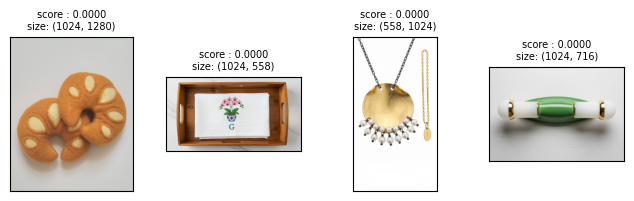

------------------ low_information images ------------------

Number of examples with this issue: 11
Examples representing most severe instances of this issue:



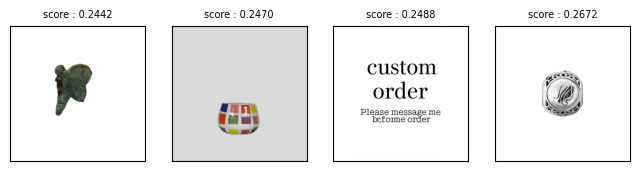

----------------- odd_aspect_ratio images ------------------

Number of examples with this issue: 4
Examples representing most severe instances of this issue:



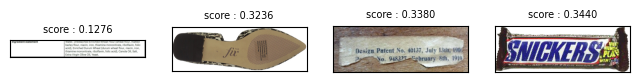

----------------------- light images -----------------------

Number of examples with this issue: 2
Examples representing most severe instances of this issue:



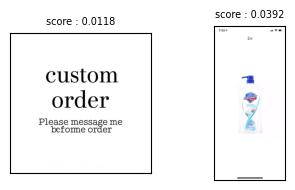

---------------------- blurry images -----------------------

Number of examples with this issue: 1
Examples representing most severe instances of this issue:



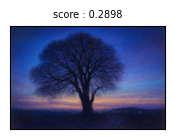

In [89]:
# What work needs to be done
imagelab = Imagelab(data_path=main_data_location) # Specify path to folder 
imagelab.find_issues() 
imagelab.report() # Produce a report of problems

---
# Step 2: General Exploration

Exploring our data

## 1. General Overview

### Describe

In [90]:
# General Overview
new_main_df.describe()

,path,label
count,3360,3360
unique,3360,2
top,data/other_datasets/created_datasets/MainData/0/0_0.jpg,0
freq,1,1740


### Info

In [91]:
# Column Datatypes?
new_main_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3360 entries, 0 to 3359
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   path    3360 non-null   object
 1   label   3360 non-null   object
dtypes: object(2)
memory usage: 52.6+ KB


### Checking Existing Labels

In [92]:
# Labels we have so far?
print(f"found {new_main_df['label'].nunique()} different image labels:")
print(f"\n\n\t{new_main_df['label'].unique()}")

found 2 different image labels:


	['0' '1']


## 2. Class Imbalances

### Overview

In [93]:
# Overview of class imbalances
print(f"Number of images? -> {len(new_main_df)}")
print(f"Number of trash types? -> {len(new_main_df['label'].value_counts())}")
print(f'\n\nNumber of images for each type?')
print(f'------\n{new_main_df["label"].value_counts()}')

Number of images? -> 3360
Number of trash types? -> 2


Number of images for each type?
------
label
0    1740
1    1620
Name: count, dtype: int64


### Histogram

Text(0, 0.5, 'Number of Images')

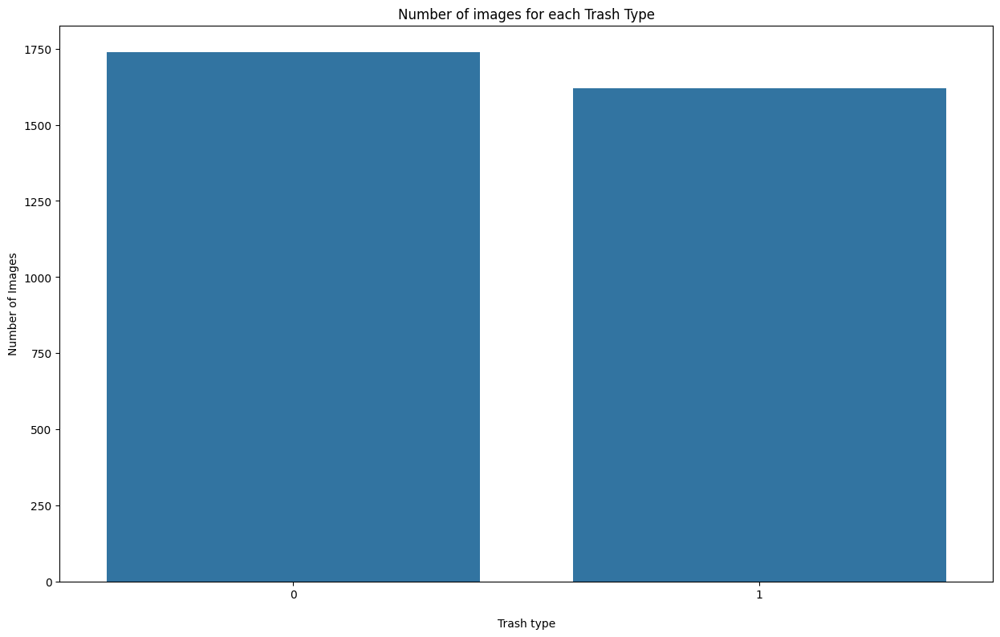

In [94]:
# Histogram
fig, ax = plt.subplots(figsize=(15, 9))
sns.countplot(data=new_main_df, x='label', order=new_main_df['label'].value_counts().index)
plt.title('Number of images for each Trash Type')
plt.xlabel('\nTrash type')
plt.ylabel('Number of Images')

## 3. Transforms

In [95]:
# Set augment variable for later training
aug = aug_transforms(
    do_flip=True,       
    max_rotate=15.0,    
    max_zoom=1.0,       
    max_warp=0.0,       
    max_lighting=0.2    # This is fastai's default
)

## 4. Dealing with Imbalances

### Weighted Random Sampling
#### Advantages
- Assigns weights to minority classes
- Does not change the size of the dataset
#### Disadvantages
- Severe overfitting
- Majority class is represented less

Total physical images: 3360
       Physical Images  Original Chance (%)  Weighted Chance (%)
label                                                           
0                 1740                51.79                48.21
1                 1620                48.21                51.79


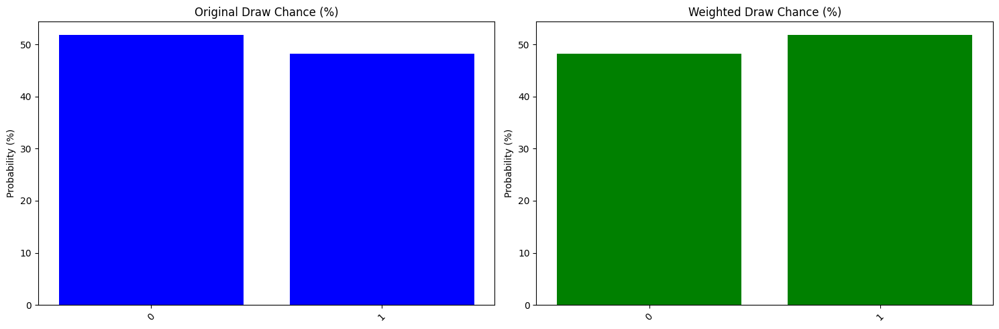

In [96]:
#########################
# Counts + calculate probabilities and weights
#########################

# Count occurrences per class
class_counts = new_main_df['label'].value_counts()
total_images = len(new_main_df)

# Calculate natural unweighted probability
orig_prob = (class_counts / total_images) * 100

# Calculate balanced sampler weights
class_weights = 1.0 / class_counts

# Normalize weights to percentages
new_prob = (class_weights / class_weights.sum()) * 100





#########################
# Comparison DF + plot probabilities
#########################

# Create simple comparison dataframe
compare_df = pd.DataFrame({
    'Physical Images': class_counts,
    'Original Chance (%)': orig_prob,
    'Weighted Chance (%)': new_prob
}).round(2)

# Show the final comparison
print(f"Total physical images: {total_images}")
print(compare_df)

# Plot the before/after probabilities
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot original draw chances
axes[0].bar(orig_prob.index, orig_prob.values, color='b')
axes[0].set_title('Original Draw Chance (%)')
axes[0].set_ylabel('Probability (%)')

# Plot balanced draw chances
axes[1].bar(new_prob.index, new_prob.values, color='g')
axes[1].set_title('Weighted Draw Chance (%)')
axes[1].set_ylabel('Probability (%)')

# Rotate labels 45 degrees
for ax in axes:
    ax.tick_params(axis='x', rotation=45)

# Show the final graphs
plt.tight_layout()
plt.show()

In [97]:
#########################
# Check weights, set variable + create sampler
#########################

print(f"{class_weights}\n")

# map weights to labels
sample_weights = new_main_df['label'].map(class_weights)

# Convert pandas to PyTorch tensor
weights_tensor = torch.tensor(sample_weights.values, dtype=torch.float)

# Create the actual PyTorch sampler
sampler = WeightedRandomSampler(
    weights=weights_tensor, 
    num_samples=len(weights_tensor), 
    replacement=True
)

print(f"Sampler created with {len(weights_tensor)} weights.")

label
0    0.000575
1    0.000617
Name: count, dtype: float64

Sampler created with 3360 weights.


## 4. Image Overview

### Sizes

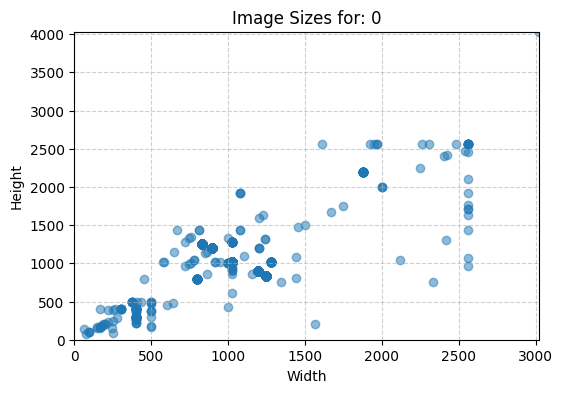

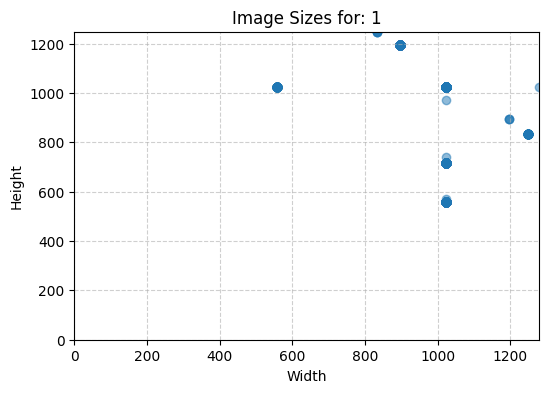

Complete!
test


In [98]:
# Get width + height
def get_dims(file_path):
    path = Path(file_path).as_posix()
    img = Image.open(path)
    width, height = img.size
    img.close()
    return width, height


# Holds width, height + label
data = {}


# Add to data variable
for path, label in new_main_df.values:

    # Get the width + height
    width, height = get_dims(path)

    # Check if trash type exists
    if label not in data:
        data[label] = {'heights': [], 'widths': []}

    # Add the width + height
    data[label]['heights'].append(height)
    data[label]['widths'].append(width)


# Plot class image sizes
for label, dims in data.items():

    # Convert to numpy arrays
    w, h = np.array(dims['widths']), np.array(dims['heights'])

    # Normalize in one line 
    # norm_w = (w - w.min()) / np.where(w == 0, 1, w)
    # norm_h = (h - h.min()) / np.where(h == 0, 1, h)

    # Scatter plot image sizes
    plt.figure(figsize=(6, 4))
    plt.scatter(w, h, alpha=0.5)
    plt.xlim(0, w.max())
    plt.ylim(0, h.max())
    plt.title(f'Image Sizes for: {label}')
    plt.xlabel('Width')
    plt.ylabel('Height')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()


print("Complete!")

# raise('ahhh')

print('test')

### Random Sample

In [99]:
# Random Sample from each class
number_of_samples = 1


# Get random path per label
sample_df = new_main_df.groupby('label').sample(n=number_of_samples).reset_index()


# Get labels + paths
labels = sample_df['label'].tolist()
paths = sample_df['path'].tolist()


# Setup our image grid
num_labels = len(labels) # Number of labels
cols = 2 # Images per row
rows = (num_labels // cols) + (num_labels % cols > 0) # Number of total rows


# Make plots to insert images
fig = make_subplots(
    rows=rows,
    cols=cols,
    subplot_titles=labels
)


# Add our chosen images
for i, path in enumerate(paths):

    # For each image
    pth = Path(path).as_posix() # Get path
    with Image.open(path) as img:

        # Convert to RGB
        img_array = np.array(img.convert("RGB"))

    # Choose row + Column for image
    row = (i // cols) + 1
    col = (i % cols) + 1

    # Add image at (row, col)
    fig.add_trace(
        go.Image(z=img_array),
        row=row,
        col=col
    )


# Clean up layout
fig.update_xaxes(showticklabels=False).update_yaxes(showticklabels=False)
fig.update_layout(
    height=300 * rows, # Scaling height by number of rows
    width=800,
    title_text="Random Sample from Each Trash Category",
    showlegend=False
)
fig.show()

---
# Step 3: Apply Techniques
Fixing our data

---
# Step 4: Image specific EDA
Exploring our data further

## 1. Understanding Color in our Images

### Color Histogram

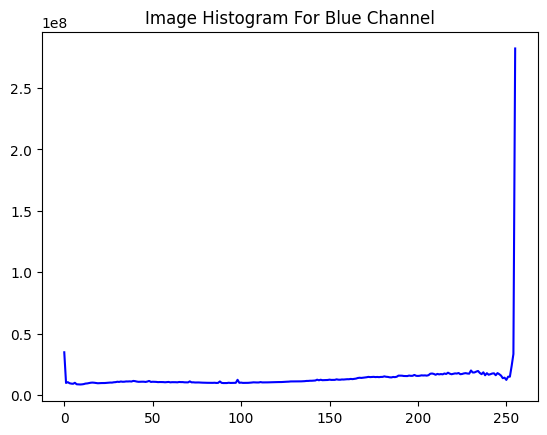

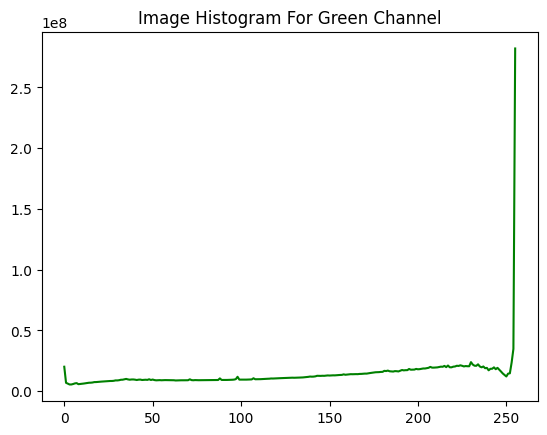

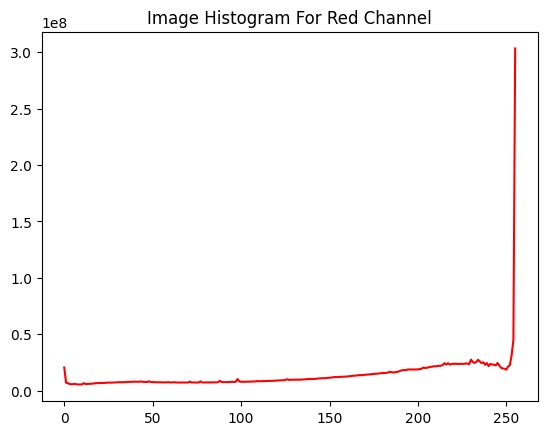

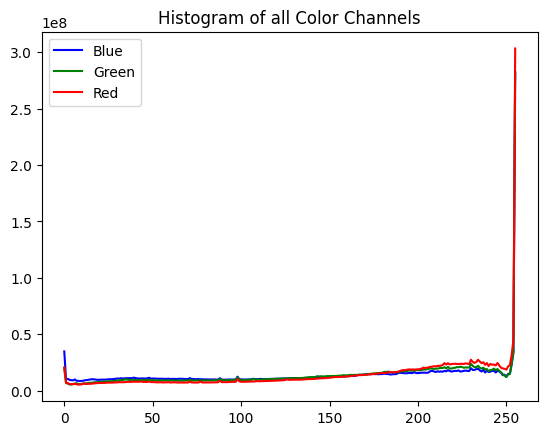

In [100]:
# Holds the channels of all Images
total_hist_b = np.zeros((256, 1))
total_hist_g = np.zeros((256, 1))
total_hist_r = np.zeros((256, 1))


# Adding images to images list
for folder in os.listdir(main_data_location):



    # For every image, add to histogram
    for image in os.listdir(f"{main_data_location}/{folder}"):
        
        # Get image path
        path = f"{main_data_location}/{folder}/{image}"

        # Get image
        img = cv2.imread(path)

        # Calculate histogram for image
        hist_b = cv2.calcHist([img], [0], None, [256], [0, 256])
        hist_g = cv2.calcHist([img], [1], None, [256], [0, 256])
        hist_r = cv2.calcHist([img], [2], None, [256], [0, 256])

        # Add to channel holders
        total_hist_b += hist_b
        total_hist_g += hist_g
        total_hist_r += hist_r


# Plot blue channel
plt.plot(total_hist_b, color='b')
plt.title('Image Histogram For Blue Channel')
plt.show()


# Plot green channel
plt.plot(total_hist_g, color='g')
plt.title('Image Histogram For Green Channel')
plt.show()


# Plot red channel
plt.plot(total_hist_r, color='r')
plt.title('Image Histogram For Red Channel')
plt.show()


# Plot all channels together
plt.plot(total_hist_b, color='b', label='Blue')
plt.plot(total_hist_g, color='g', label='Green')
plt.plot(total_hist_r, color='r', label='Red')
plt.title('Histogram of all Color Channels')
plt.legend()
plt.show()

### Color Histogram (Alternative)

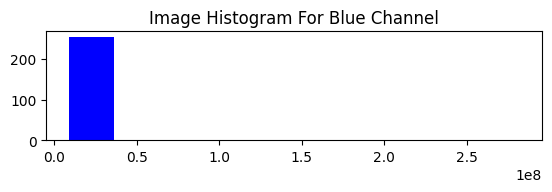

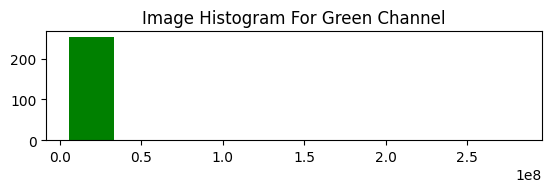

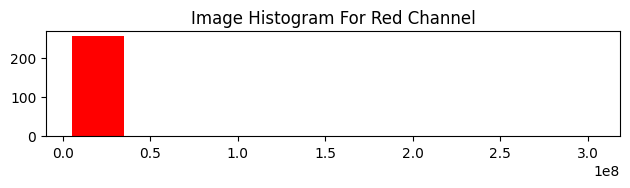

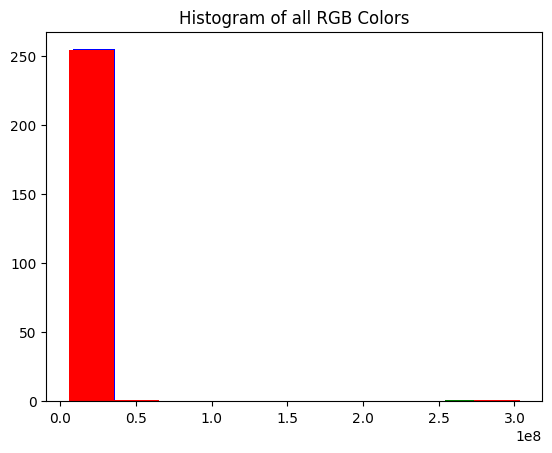

In [101]:
# Holds the channels of all Images
total_hist_b = np.zeros((256, 1))
total_hist_g = np.zeros((256, 1))
total_hist_r = np.zeros((256, 1))


# Adding images to images list
for folder in os.listdir(main_data_location):

    # For every image, add to histogram
    for image in os.listdir(f"{main_data_location}/{folder}"):
        
        # Get image path
        path = f"{main_data_location}/{folder}/{image}"

        # Get image
        img = cv2.imread(path)

        # Calculate histogram for image
        hist_b = cv2.calcHist([img], [0], None, [256], [0, 256])
        hist_g = cv2.calcHist([img], [1], None, [256], [0, 256])
        hist_r = cv2.calcHist([img], [2], None, [256], [0, 256])

        # Add to channel holders
        total_hist_b += hist_b
        total_hist_g += hist_g
        total_hist_r += hist_r


# Plot blue channel
plt.figure()
plt.subplot(3, 1, 1)
plt.title("Image Histogram For Blue Channel")
plt.hist(total_hist_b, color="blue")

# Plot green channel
plt.figure()
plt.subplot(3, 1, 1)
plt.title("Image Histogram For Green Channel")
plt.hist(total_hist_g, color="green")

# Plot red channel
plt.figure()
plt.subplot(3, 1, 1)
plt.title("Image Histogram For Red Channel")
plt.hist(total_hist_r, color="red")

# For a clearer view
plt.tight_layout()
plt.show()

# Plot all channels together
plt.title("Histogram of all RGB Colors")
plt.hist(total_hist_b, color="blue")
plt.hist(total_hist_g, color="green")
plt.hist(total_hist_r, color="red")
plt.show()

### Color Histograms for every class

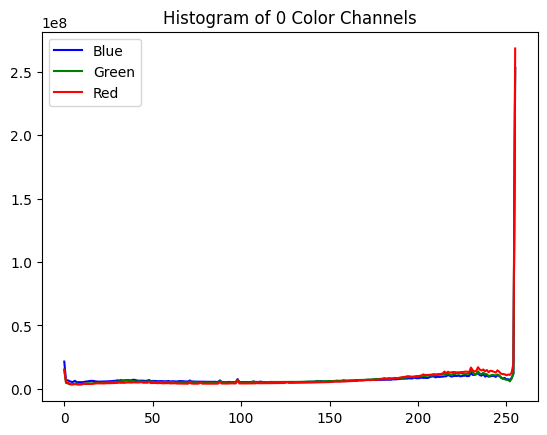

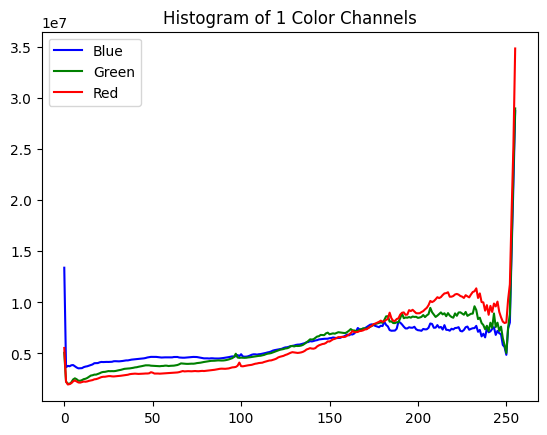

In [102]:
# Adding images to images list
for folder in os.listdir(main_data_location):

    # Holds the channels of all Images
    total_hist_b = np.zeros((256, 1))
    total_hist_g = np.zeros((256, 1))
    total_hist_r = np.zeros((256, 1))

    # For every image, add to histogram
    for image in os.listdir(f"{main_data_location}/{folder}"):
        
        # Get image path
        path = f"{main_data_location}/{folder}/{image}"

        # Get image
        img = cv2.imread(path)

        # Calculate histogram for image
        hist_b = cv2.calcHist([img], [0], None, [256], [0, 256])
        hist_g = cv2.calcHist([img], [1], None, [256], [0, 256])
        hist_r = cv2.calcHist([img], [2], None, [256], [0, 256])

        # Add to channel holders
        total_hist_b += hist_b
        total_hist_g += hist_g
        total_hist_r += hist_r

    # Plot all channels together
    plt.plot(total_hist_b, color='b', label='Blue')
    plt.plot(total_hist_g, color='g', label='Green')
    plt.plot(total_hist_r, color='r', label='Red')
    plt.title(f'Histogram of {folder} Color Channels')
    plt.legend()
    plt.show()

### Color Histograms (Alternative) for every class

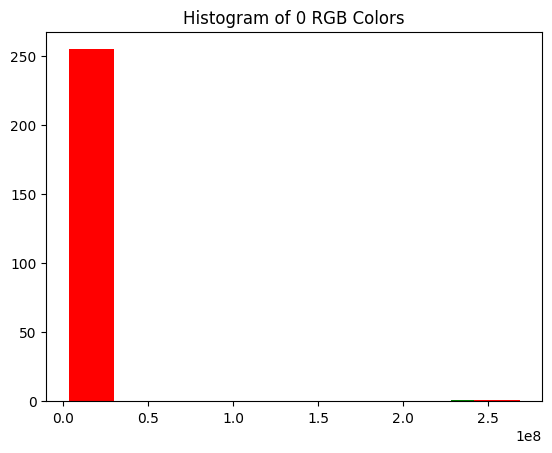

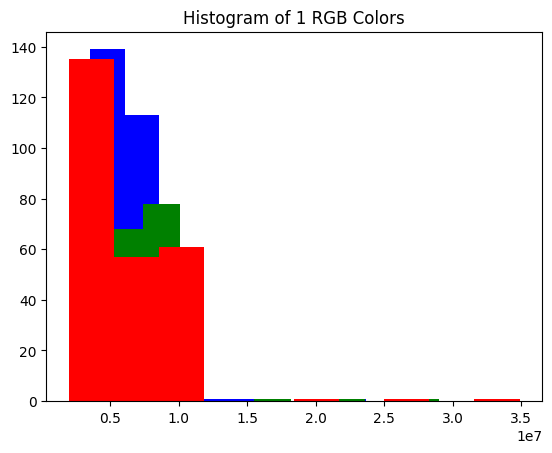

In [103]:
# Adding images to images list
for folder in os.listdir(main_data_location):

    # Holds the channels of all Images
    total_hist_b = np.zeros((256, 1))
    total_hist_g = np.zeros((256, 1))
    total_hist_r = np.zeros((256, 1))

    # For every image, add to histogram
    for image in os.listdir(f"{main_data_location}/{folder}"):
        
        # Get image path
        path = f"{main_data_location}/{folder}/{image}"

        # Get image
        img = cv2.imread(path)

        # Calculate histogram for image
        hist_b = cv2.calcHist([img], [0], None, [256], [0, 256])
        hist_g = cv2.calcHist([img], [1], None, [256], [0, 256])
        hist_r = cv2.calcHist([img], [2], None, [256], [0, 256])

        # Add to channel holders
        total_hist_b += hist_b
        total_hist_g += hist_g
        total_hist_r += hist_r

    # Plot all channels together
    plt.title(f"Histogram of {folder} RGB Colors")
    plt.hist(total_hist_b, color="blue")
    plt.hist(total_hist_g, color="green")
    plt.hist(total_hist_r, color="red")
    plt.show()

### Brightness Outliers

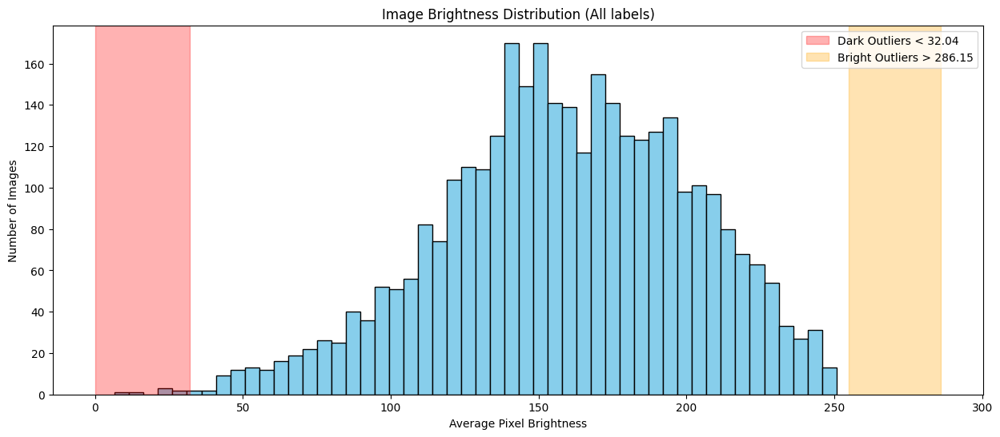

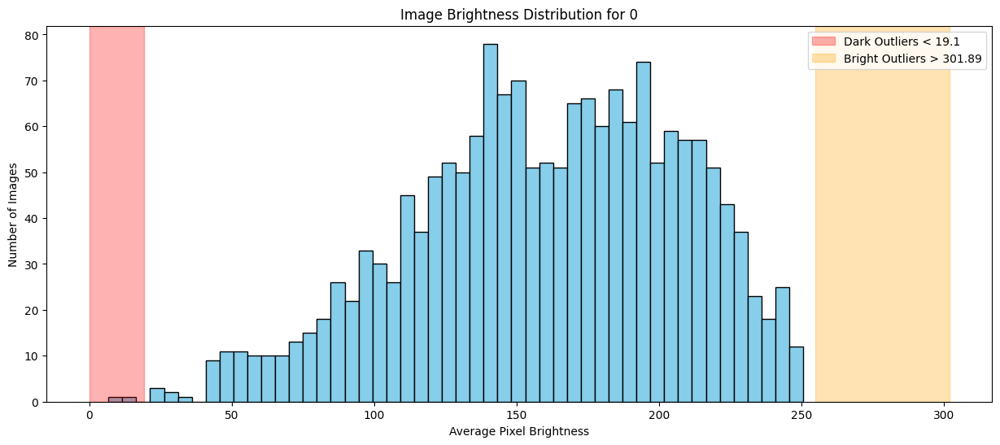

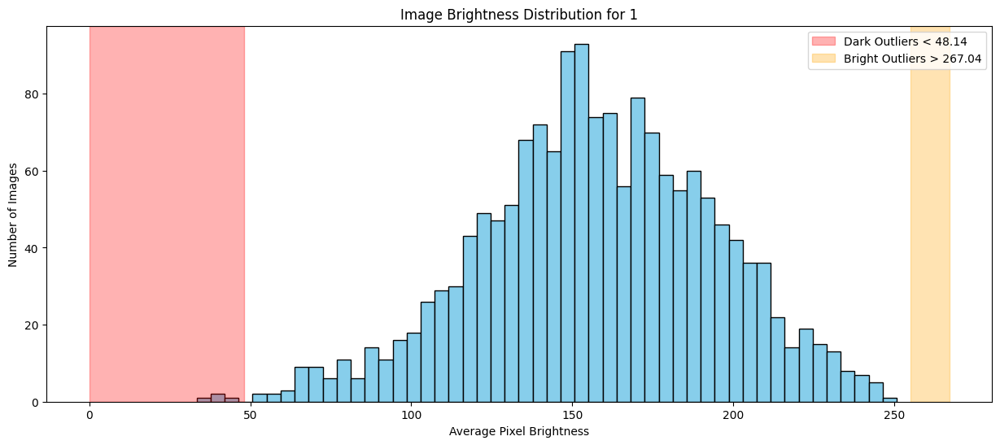

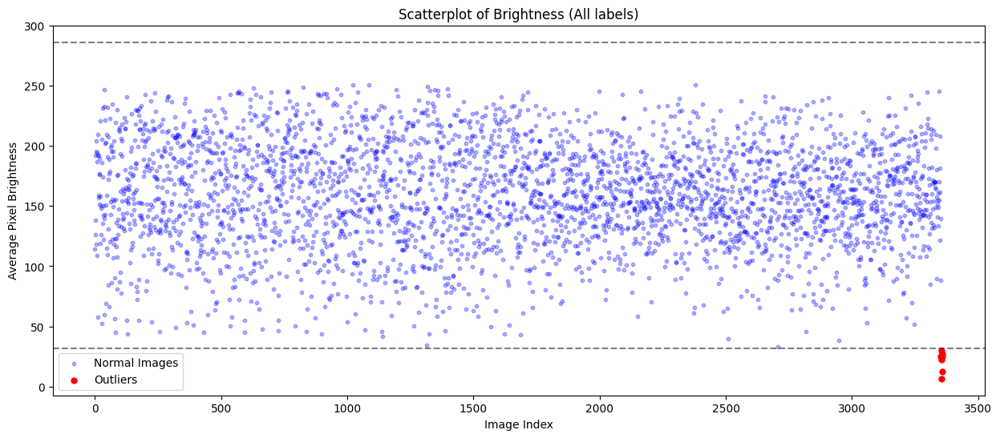

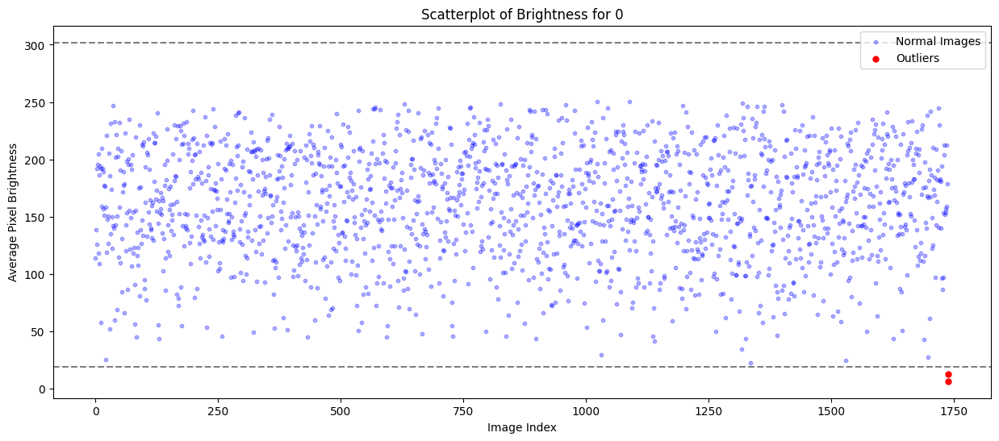

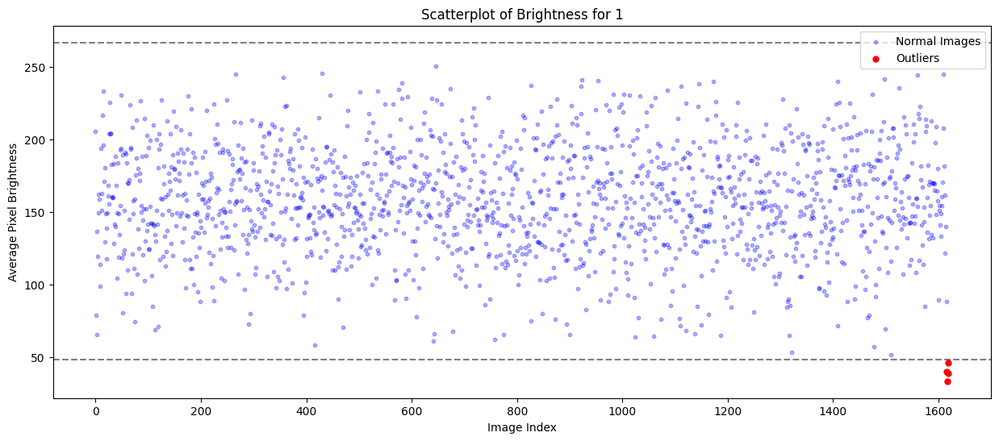

In [104]:
# Get average pixel brightness
new_main_df['brightness'] = new_main_df['path'].apply(lambda x: cv2.imread(x, cv2.IMREAD_GRAYSCALE).mean()) # Get mean from grayscale

# Define z-score outliers
z_threshold = 3
global_mean = new_main_df['brightness'].mean()
global_std = new_main_df['brightness'].std()
global_lower = global_mean - z_threshold * global_std
global_upper = global_mean + z_threshold * global_std

z_scores = (new_main_df['brightness'] - global_mean) / global_std
outliers = new_main_df[(z_scores.abs() > z_threshold)]

# Create a histogram
plt.figure(figsize=(15, 6))
plt.hist(new_main_df['brightness'], bins=50, color='skyblue', edgecolor='black')

# Highlight the outliers (using dynamic global values)
plt.axvspan(0, global_lower, color='red', alpha=0.3, label=f'Dark Outliers < {round(global_lower, 2)}')
plt.axvspan(global_upper, 255, color='orange', alpha=0.3, label=f'Bright Outliers > {round(global_upper, 2)}')

# Add plot labels
plt.title('Image Brightness Distribution (All labels)')
plt.xlabel('Average Pixel Brightness')
plt.ylabel('Number of Images')
plt.legend()
plt.show()

# Loop through unique labels for Histograms
for folder in new_main_df['label'].unique():
    folder_data = new_main_df[new_main_df['label'] == folder]['brightness']
    f_mean = folder_data.mean()
    f_std = folder_data.std()
    f_lower = f_mean - z_threshold * f_std
    f_upper = f_mean + z_threshold * f_std

    # Create a histogram
    plt.figure(figsize=(15, 6))
    plt.hist(folder_data, bins=50, color='skyblue', edgecolor='black')

    # Highlight the outliers (fixed labels to be folder-specific)
    plt.axvspan(0, f_lower, color='red', alpha=0.3, label=f'Dark Outliers < {round(f_lower, 2)}')
    plt.axvspan(f_upper, 255, color='orange', alpha=0.3, label=f'Bright Outliers > {round(f_upper, 2)}')

    # Add plot labels
    plt.title(f'Image Brightness Distribution for {folder}')
    plt.xlabel('Average Pixel Brightness')
    plt.ylabel('Number of Images')
    plt.legend()
    plt.show()

# Create a Scatter plot
plt.figure(figsize=(15, 6))

# Separate normal data from outliers (replaced 240 with global_upper)
normal_data = new_main_df[(new_main_df['brightness'] >= global_lower) & (new_main_df['brightness'] <= global_upper)]

# Plot the normal images in blue
plt.scatter(range(len(normal_data)), normal_data['brightness'],
            color='blue', alpha=0.3, s=10, label='Normal Images')

# Plot the outliers in red (replaced 240 with global_upper)
plt.scatter(range(len(normal_data), len(normal_data) + len(outliers)),
            outliers['brightness'],
            color='red', s=25, label='Outliers')

# Draw threshold lines
plt.axhline(y=global_lower, color='black', linestyle='--', alpha=0.5)
plt.axhline(y=global_upper, color='black', linestyle='--', alpha=0.5)

# Add plot labels
plt.title('Scatterplot of Brightness (All labels)')
plt.xlabel('Image Index')
plt.ylabel('Average Pixel Brightness')
plt.legend()
plt.show()

# Loop through unique labels for Scatter plots
for folder in new_main_df['label'].unique():
    folder_mask = new_main_df['label'] == folder
    f_mean = new_main_df[folder_mask]['brightness'].mean()
    f_std = new_main_df[folder_mask]['brightness'].std()
    f_lower = f_mean - z_threshold * f_std
    f_upper = f_mean + z_threshold * f_std

    # Create a Scatter plot
    plt.figure(figsize=(15, 6))

    # Separate normal data from outliers (replaced 240 with f_upper and fixed logic)
    normal_data = new_main_df[folder_mask & (new_main_df['brightness'] >= f_lower) & (new_main_df['brightness'] <= f_upper)]
    outliers = new_main_df[folder_mask & ((new_main_df['brightness'] < f_lower) | (new_main_df['brightness'] > f_upper))]

    # Plot the normal images in blue
    plt.scatter(range(len(normal_data)), normal_data['brightness'],
            color='blue', alpha=0.3, s=10, label='Normal Images')

    # Plot the outliers in red
    plt.scatter(range(len(normal_data), len(normal_data) + len(outliers)),
            outliers['brightness'],
            color='red', s=25, label='Outliers')

    # Draw threshold lines (fixed to use folder-specific stats)
    plt.axhline(y=f_upper, color='black', linestyle='--', alpha=0.5)
    plt.axhline(y=f_lower, color='black', linestyle='--', alpha=0.5)

    # Add plot labels
    plt.title(f'Scatterplot of Brightness for {folder}')
    plt.xlabel('Image Index')
    plt.ylabel('Average Pixel Brightness')
    plt.legend()
    plt.show()

## 2. Understanding Texture (GLCM)
- Color and shape are not enough...
- Enter GLCM (Gray-Level Co-occurrence Matrix): this helps the model analyze the roughness or smoothness of the material

In [105]:
# Define GLCM feature extractor
def get_glcm_features(image_path):
    # Read image in Grayscale
    img_gray = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    
    # Return zeros if none
    if img_gray is None:
        return np.zeros(4, dtype=np.float32)
        
    # Resize to standardize texture
    img_gray = cv2.resize(img_gray, (224, 224))
    
    # Compute the GLCM matrix 
    glcm = graycomatrix(img_gray, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
    
    # Extract texture properties
    contrast = graycoprops(glcm, 'contrast')[0, 0]
    correlation = graycoprops(glcm, 'correlation')[0, 0]
    energy = graycoprops(glcm, 'energy')[0, 0]
    homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
    
    # Return flat numpy array
    return np.array([contrast, correlation, energy, homogeneity], dtype=np.float32)

=== STATS FOR 0 ===
  Contrast:
    Q1: 221.68 | Q3: 754.46 | IQR: 532.78
    Outlier Bounds: -577.48 to 1553.62
    Total Outliers Detected: 88

  Homogeneity:
    Q1: 0.22 | Q3: 0.53 | IQR: 0.31
    Outlier Bounds: -0.24 to 0.99
    Total Outliers Detected: 0

  Energy:
    Q1: 0.02 | Q3: 0.14 | IQR: 0.12
    Outlier Bounds: -0.15 to 0.32
    Total Outliers Detected: 289

  Correlation:
    Q1: 0.87 | Q3: 0.96 | IQR: 0.09
    Outlier Bounds: 0.73 to 1.09
    Total Outliers Detected: 91




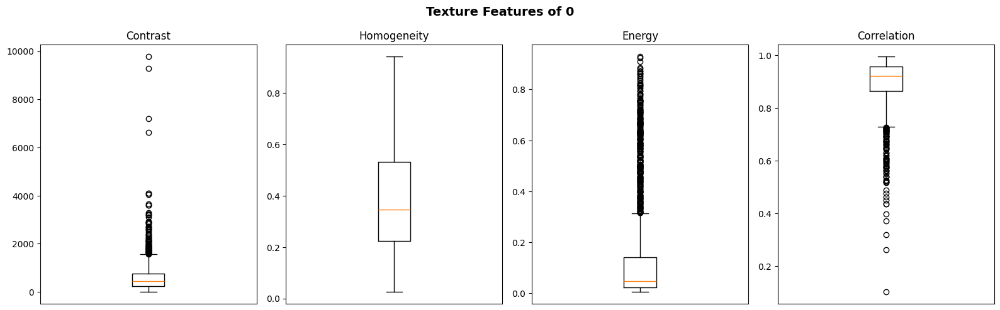

=== STATS FOR 1 ===
  Contrast:
    Q1: 255.96 | Q3: 774.12 | IQR: 518.16
    Outlier Bounds: -521.27 to 1551.35
    Total Outliers Detected: 68

  Homogeneity:
    Q1: 0.24 | Q3: 0.51 | IQR: 0.27
    Outlier Bounds: -0.16 to 0.91
    Total Outliers Detected: 1

  Energy:
    Q1: 0.03 | Q3: 0.08 | IQR: 0.05
    Outlier Bounds: -0.05 to 0.16
    Total Outliers Detected: 196

  Correlation:
    Q1: 0.87 | Q3: 0.95 | IQR: 0.08
    Outlier Bounds: 0.75 to 1.07
    Total Outliers Detected: 79




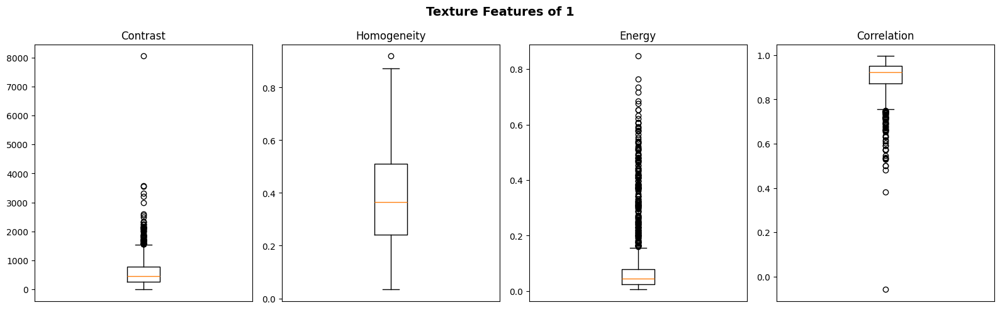

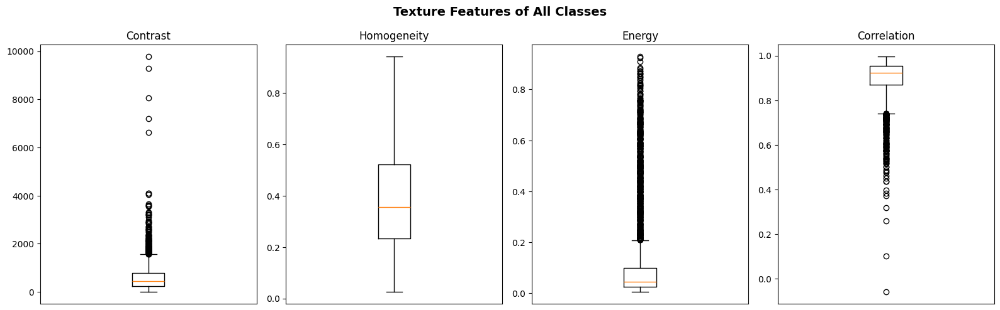

In [106]:
# Find quartiles and IQR bounds
def print_boxplot_stats(data, feature_name):
    # Calculate the 25th percentile
    q1 = np.percentile(data, 25)
    
    # Calculate the 75th percentile
    q3 = np.percentile(data, 75)
    
    # Find the interquartile range
    iqr = q3 - q1
    
    # Calculate the lower boundary
    lower_bound = q1 - (1.5 * iqr)
    
    # Calculate the upper boundary
    upper_bound = q3 + (1.5 * iqr)
    
    # Find the outlier data points
    outliers = [x for x in data if x < lower_bound or x > upper_bound]
    
    # Print out the calculated stats
    print(f"  {feature_name}:")
    print(f"    Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
    print(f"    Outlier Bounds: {lower_bound:.2f} to {upper_bound:.2f}")
    print(f"    Total Outliers Detected: {len(outliers)}\n")

# Hold all class features
all_contrasts = []
all_homogeneities = []
all_energies = []
all_correlations = []

# Iterate through every folder
for folder in os.listdir(main_data_location):
    # Hold single class features
    contrasts = []
    homogeneities = []
    energies = []
    correlations = []

    # Loop through folder images
    for image in os.listdir(f"{main_data_location}/{folder}"):
        # Get full image path
        path = f"{main_data_location}/{folder}/{image}"

        # Extract features using function
        features = get_glcm_features(path)

        # Skip if image missing
        if np.all(features == 0):
            continue

        # Unpack the returned features
        con, cor, ene, hom = features

        # Add to individual lists
        contrasts.append(con)
        correlations.append(cor)
        energies.append(ene)
        homogeneities.append(hom)

        # Add to all classes
        all_contrasts.append(con)
        all_correlations.append(cor)
        all_energies.append(ene)
        all_homogeneities.append(hom)

    # Print math before plotting
    print(f"=== STATS FOR {folder.upper()} ===")
    print_boxplot_stats(contrasts, "Contrast")
    print_boxplot_stats(homogeneities, "Homogeneity")
    print_boxplot_stats(energies, "Energy")
    print_boxplot_stats(correlations, "Correlation")
    print("==================================\n")

    # Plot features in separate subplots
    fig, axes = plt.subplots(1, 4, figsize=(16, 5))
    fig.suptitle(f"Texture Features of {folder}", fontsize=14, fontweight="bold")

    # Plot the contrast features
    axes[0].boxplot(contrasts)
    axes[0].set_title("Contrast")
    axes[0].set_xticks([])  

    # Plot the homogeneity features
    axes[1].boxplot(homogeneities)
    axes[1].set_title("Homogeneity")
    axes[1].set_xticks([])

    # Plot the energy features
    axes[2].boxplot(energies)
    axes[2].set_title("Energy")
    axes[2].set_xticks([])

    # Plot the correlation features
    axes[3].boxplot(correlations)
    axes[3].set_title("Correlation")
    axes[3].set_xticks([])

    # Adjust layout and show
    plt.tight_layout()
    plt.show()

# Plot all classes together
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
fig.suptitle("Texture Features of All Classes", fontsize=14, fontweight="bold")

# Plot combined contrast features
axes[0].boxplot(all_contrasts)
axes[0].set_title("Contrast")
axes[0].set_xticks([])

# Plot combined homogeneity features
axes[1].boxplot(all_homogeneities)
axes[1].set_title("Homogeneity")
axes[1].set_xticks([])

# Plot combined energy features
axes[2].boxplot(all_energies)
axes[2].set_title("Energy")
axes[2].set_xticks([])

# Plot combined correlation features
axes[3].boxplot(all_correlations)
axes[3].set_title("Correlation")
axes[3].set_xticks([])

# Adjust layout and show
plt.tight_layout()
plt.show()

## 3. Frequency Domain Analysis (Using Fast Fourier Transform)
Understanding the image through the frequency Spectrum

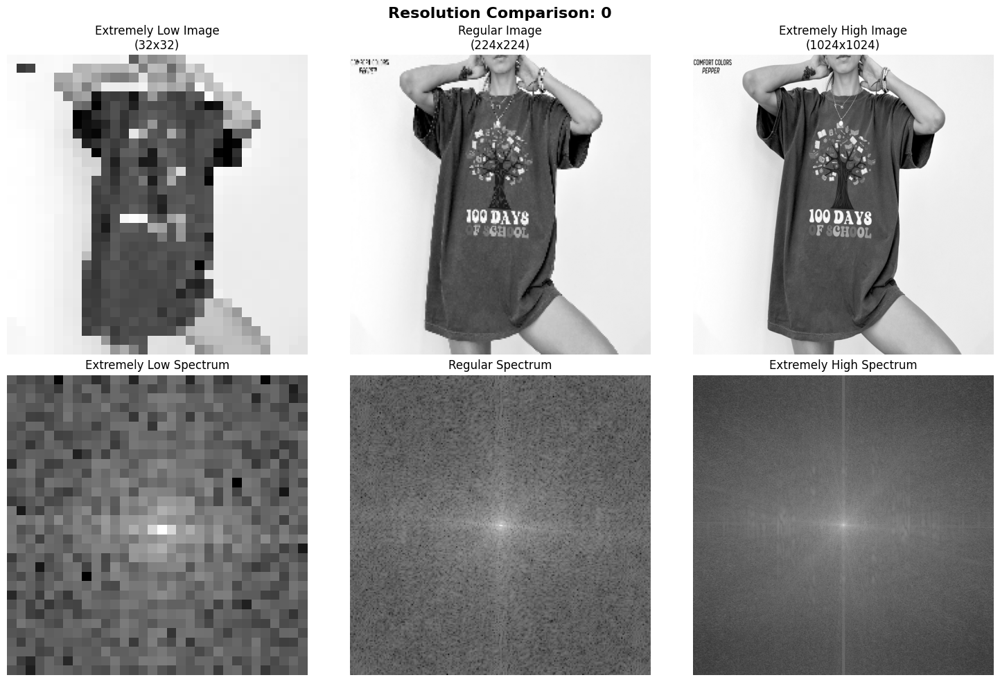

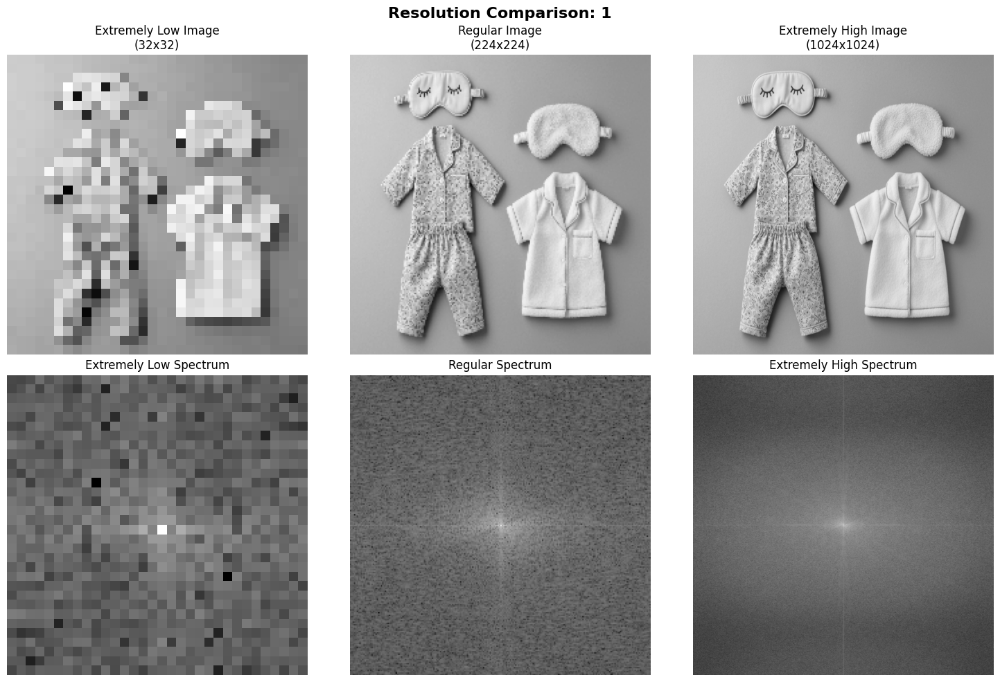

In [107]:
# Define the three test resolutions
resolutions = {
    "Extremely Low": (32, 32), 
    "Regular": (224, 224), 
    "Extremely High": (1024, 1024)
}

# Iterate through every folder
for folder in os.listdir(main_data_location):
    
    # Get the folder path
    folder_path = f"{main_data_location}/{folder}"
    
    # Get all image names
    all_images = os.listdir(folder_path)
    
    # Skip empty folders safely
    if not all_images:
        continue
        
    # Pick one random image
    random_image = random.choice(all_images)
    
    # Get full image path
    path = f"{folder_path}/{random_image}"

    # Read image in grayscale
    img_raw = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    # Skip if image missing
    if img_raw is None:
        continue

    # Create a 2x3 plot grid
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Set the main title
    fig.suptitle(f"Resolution Comparison: {folder.upper()}", fontsize=16, fontweight="bold")

    # Loop through the three resolutions
    for i, (res_name, size) in enumerate(resolutions.items()):
        
        # Resize to specific dimensions
        img_resized = cv2.resize(img_raw, size)

        # Apply Fast Fourier Transform
        f_transform = np.fft.fft2(img_resized)

        # Shift the low frequencies
        f_shift = np.fft.fftshift(f_transform)

        # Calculate the magnitude spectrum
        magnitude_spectrum = 20 * np.log(np.abs(f_shift) + 1)

        # Plot the resized image
        axes[0, i].imshow(img_resized, cmap='gray')
        axes[0, i].set_title(f"{res_name} Image\n({size[0]}x{size[1]})")
        axes[0, i].axis('off')

        # Plot the magnitude spectrum
        axes[1, i].imshow(magnitude_spectrum, cmap='gray')
        axes[1, i].set_title(f"{res_name} Spectrum")
        axes[1, i].axis('off')

    # Adjust layout and show
    plt.tight_layout()
    plt.show()

## 3. Observing Random Outliers

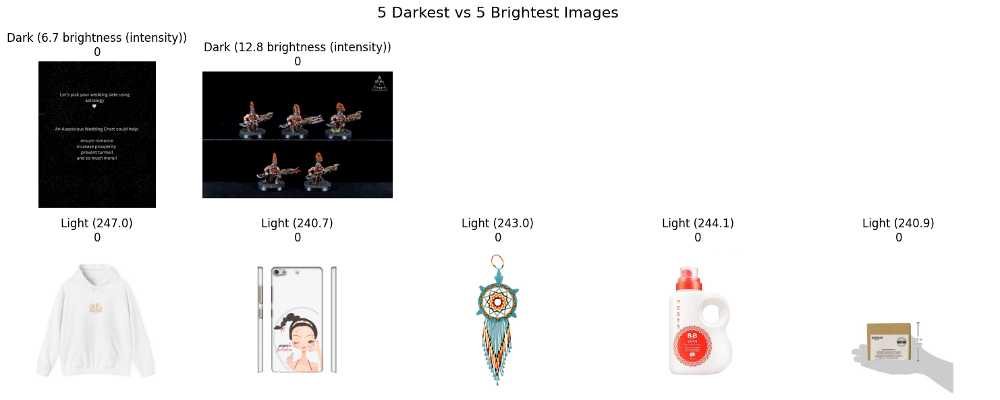

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3360 entries, 0 to 3359
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   path    3360 non-null   object
 1   label   3360 non-null   object
dtypes: object(2)
memory usage: 52.6+ KB
None


In [108]:
# Grab 5 dark and 5 light
dark_outliers = new_main_df[new_main_df['brightness'] < 20].head(5)
light_outliers = new_main_df[new_main_df['brightness'] > 240].head(5)

# Check how many we found
n_dark = len(dark_outliers)
n_light = len(light_outliers)

# Plot our 10 images
if n_dark == 0 and n_light == 0: # If no outliers...
    print("No outliers found! Your dataset has no extreme dark or light images based on these thresholds.")

# Else, plot our 10 images
else:

    # 2 row, 5 column grid
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    fig.suptitle("5 Darkest vs 5 Brightest Images", fontsize=16)

    # Plot Dark Outliers
    for i in range(5):
        
        # Plot on first row
        ax = axes[0, i] 

        # Read and Plot image
        if i < n_dark:
            row = dark_outliers.iloc[i]
            img = cv2.imread(row['path'])
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Fix colors for Matplotlib
            ax.imshow(img)
            ax.set_title(f"Dark ({row['brightness']:.1f} brightness (intensity))\n{row['label']}")
        ax.axis('off') # Hide grid lines and numbers

    # 4. Plot Light Outliers (Bottom Row / Index 1)
    for i in range(5):

        # Plot on second row
        ax = axes[1, i]

        # Read and Plot image
        if i < n_light:
            row = light_outliers.iloc[i]
            img = cv2.imread(row['path'])
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # Fix colors for Matplotlib
            ax.imshow(img)
            ax.set_title(f"Light ({row['brightness']:.1f})\n{row['label']}")
        ax.axis('off') # Hide grid lines and numbers

    plt.tight_layout()
    plt.show()


# Drop brightness column
new_main_df = new_main_df.drop(columns="brightness")


# Info on new_main_df
print(new_main_df.info())

---
# Step 5: Training

Creating, Testing and Saving our model

## 1. Training

In [109]:
# Container for our data
datablock = DataBlock(
    blocks=(
        ImageBlock,
        CategoryBlock,
    ),
    get_x=get_x,
    get_y=get_y,
    item_tfms=RandomResizedCrop(224, min_scale=0.8),
    batch_tfms=aug
)


# Baseline
baseline_dls = datablock.dataloaders(
    new_main_df,
    bs=8,
    num_workers=8,  # start here, adjust up/down
    pin_memory=True,
    sampler = sampler
)


# Oversampling

# Test Dataloader

# baseline
baseline_test_dl = baseline_dls.test_dl(test_df, with_labels=True)
baseline_valid_dl = baseline_dls.test_dl(valid_df, with_labels=True)


# Oversampling

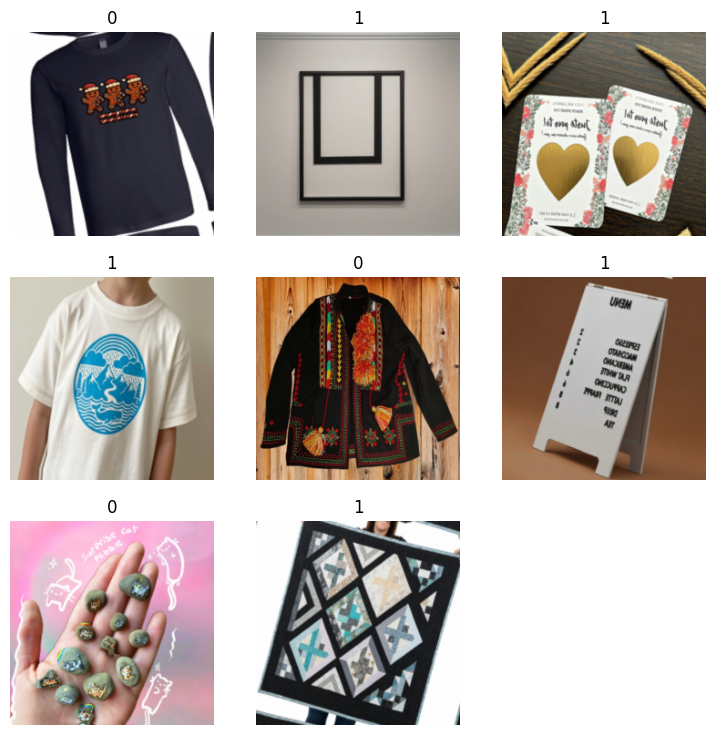

In [110]:
baseline_dls.show_batch(nrows=3, ncols=3) # lets show some data

In [111]:
# clear gpu data before training
torch.cuda.empty_cache()

In [112]:
# Define techniques and architectures
techniques = ["Baseline"]
models = ["Basic_CNN"]

# Loop over each technique
for tech in techniques:

    # Make directory for technique
    tech_dir = f"models/{tech}"
    os.makedirs(tech_dir, exist_ok=True)

    # Loop over each model
    for mod in models:

        # Define final file path
        model_path = f"{tech_dir}/{mod}.pkl"

        # Skip if already exists
        if os.path.isfile(model_path):
            print(f"{tech} - {mod}: model is trained!")
            continue

        print(f"Training {mod} on {tech}...")

        # Match string to dataloader
        match tech:
            case "Baseline":
                current_dls = baseline_dls

        # Match string to architecture
        match mod:
            case "Basic_CNN":
                arch = resnet18  # Using resnet18 as a standard basic CNN

        # Initialize the vision learner
        learner = vision_learner(current_dls, arch, metrics=accuracy)

        # Remove standard progress bar
        learner.remove_cb(ProgressCallback)

        # Fine tune our model
        learner.fine_tune(3, base_lr=3e-3, freeze_epochs=0)

        # Export the final model
        learner.export(model_path)

Training Basic_CNN on Baseline...
[0, 0.8782830834388733, 0.6491058468818665, 0.7291666865348816, '00:40']
[1, 0.5762033462524414, 0.454409658908844, 0.8095238208770752, '00:41']
[2, 0.45672690868377686, 0.4136594235897064, 0.8184523582458496, '00:42']


---
# Step 6: Analysis
Observing how our model predicts

---
## 1. Shapley Analysis
What is our model looking at?

In [113]:
# Define technique and model lists
techniques = ["Baseline"]
models = ["Basic_CNN"]

# Create folder for SHAP plots
os.makedirs("shap_plots", exist_ok=True)

# Set specific class to test
class_to_test = '1'

# Loop over every data technique
for tech in techniques:

    # Loop over every model architecture
    for mod in models:

        # Define specific model file path
        model_path = f"models/{tech}/{mod}.pkl"

        # Check if model file exists
        if os.path.isfile(model_path):

            # Print current model being evaluated
            print(f"Generating SHAP for {tech} {mod}...")

            # Load the saved model file
            learner = load_learner(model_path)

            # Filter dataframe for specific class
            class_df = valid_df[valid_df['label'] == class_to_test]

            # Grab first five image paths
            img_paths = class_df['path'].values[:5]

            # Convert images to numpy arrays
            X = np.stack([
                cv2.resize(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB), (256, 256)) 
                for p in img_paths
            ])

            # Define tensor conversion function
            def f(x):
                # Convert to float tensor safely
                x_tensor = torch.tensor(x).float()
                # Permute the tensor dimensions safely
                x_tensor = x_tensor.permute(0, 3, 1, 2)
                # Scale pixel values down safely
                x_tensor = x_tensor / 255.0
                # Move tensor to GPU safely
                x_tensor = x_tensor.to(learner.dls.device)
                # Return numpy array of predictions
                return learner.model(x_tensor).detach().cpu().numpy()

            # Build the image masker safely
            masker = shap.maskers.Image("blur(128,128)", X[0].shape)

            # Get unique labels from dataframe
            # unique_labels = test_df['label'].unique()
            
            unique_labels = list(learner.dls.vocab)

            # Initialize the SHAP explainer safely
            explainer = shap.Explainer(f, masker, output_names=unique_labels)

            # Calculate the SHAP values safely
            shap_values = explainer(
                X[0:4],
                max_evals=500,
                batch_size=50,
                outputs=shap.Explanation.argsort.flip[0:4],
            )

            # Generate the SHAP image plot
            shap.image_plot(shap_values, show=False)

            # Save plot to hard drive
            plt.savefig(f"shap_plots/{tech}_{mod}.png", bbox_inches='tight')

            # Clear matplotlib figure safely
            plt.clf()

Generating SHAP for Baseline Basic_CNN...


c:\Users\Danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\fastai\learner.py:455: UserWarning:

load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.

PartitionExplainer explainer: 5it [00:12, 12.21s/it]               


<Figure size 900x1250 with 0 Axes>

---
## 2. Cam-Grad Visualization
Similar to Shapley Analysis (how does our model predict)
- produces heatmaps to visualize which image parts most influenced a CNN's decision

In [114]:
# Define techniques and model lists
techniques = ["Baseline"]
models = ["Basic_CNN"]

# Create folder for Grad-CAM plots
os.makedirs("gradcam_plots", exist_ok=True)

# Define the Grad-CAM class safely
class SimpleGradCAM:
    def __init__(self, model, layer):
        # Store the model reference safely
        self.model = model
        # Hook the forward pass safely
        layer.register_forward_hook(self.save_act)
        # Hook the backward pass safely
        layer.register_full_backward_hook(self.save_grad)

    # Save the output activations safely
    def save_act(self, m, i, o): self.act = o

    # Save the output gradients safely
    def save_grad(self, m, i, o): self.grad = o[0]

    # Calculate the class activation map
    def get_cam(self, x, cls_idx):
        # Zero out the model gradients
        self.model.zero_grad()
        # Run the forward pass safely
        out = self.model(x)
        # Run the backward pass safely
        out[0, cls_idx].backward()
        # Average the feature gradients safely
        w = self.grad.mean(dim=(2, 3), keepdim=True)
        # Weight the output activations safely
        cam = (w * self.act).sum(1).squeeze()
        # Detach and move to CPU
        cam = cam.detach().cpu().numpy()
        # Keep positive values only safely
        return np.maximum(cam, 0)

# Loop over every data technique
for tech in techniques:
    # Loop over every model architecture
    for mod in models:
        # Define specific model file path
        model_path = f"models/{tech}/{mod}.pkl"

        # Check if model file exists
        if os.path.isfile(model_path):
            # Print current model being evaluated
            print(f"Generating Grad-CAM for {tech} {mod}...")

            # Load the saved model file
            learner = load_learner(model_path)

            # Get all dataset classes safely
            classes = list(learner.dls.vocab)

            # Set up model device safely
            dev = learner.dls.device
            learner.model.to(dev)

            try:
                # Target last CNN layer safely
                target = learner.model[0][-1]
                # Initialize the Grad-CAM object
                gcam = SimpleGradCAM(learner.model, target)
            except:
                # Skip if architecture is incompatible
                print(f"Skipping {mod}: layer structure unsupported.")
                continue

            # Set up plot size safely
            plt.figure(figsize=(10, 4 * len(classes)))

            # Loop over all dataset classes
            for i, cls_name in enumerate(classes):
                # Filter dataframe for specific class
                class_df = valid_df[valid_df['label'] == cls_name]

                # Get the first image path
                path = class_df['path'].iloc[0]

                # Load the image with OpenCV
                img = cv2.imread(str(path))
                # Convert color format to RGB
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                # Prepare image for the model
                x = torch.tensor(img).float()
                # Permute the tensor dimensions safely
                x = x.permute(2, 0, 1)
                # Scale between zero and one
                x = x.div(255.0).unsqueeze(0).to(dev)

                # Generate the raw heatmap safely
                cam = gcam.get_cam(x, i)

                # Resize to original dimensions safely
                cam = cv2.resize(cam, (img.shape[1], img.shape[0]))
                # Scale heatmap zero to one
                cam = cam / (cam.max() + 1e-10)

                # Create heatmap color overlay safely
                hm = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
                # Convert color format to RGB
                hm = cv2.cvtColor(hm, cv2.COLOR_BGR2RGB)
                # Combine image and heatmap safely
                overlay = cv2.addWeighted(img, 0.6, hm, 0.4, 0)

                # Plot the original image safely
                plt.subplot(len(classes), 2, 2*i + 1)
                plt.imshow(img); plt.axis('off')
                plt.title(f"Original: {cls_name}")

                # Plot the heatmap overlay safely
                plt.subplot(len(classes), 2, 2*i + 2)
                plt.imshow(overlay); plt.axis('off')
                plt.title(f"Grad-CAM: {cls_name}")

            # Adjust the plot layout safely
            plt.tight_layout()
            # Save plot to hard drive
            plt.savefig(f"gradcam_plots/{tech}_{mod}.png", bbox_inches='tight')
            # Clear matplotlib figure safely
            plt.clf()
            # Close the figure completely safely
            plt.close()

Generating Grad-CAM for Baseline Basic_CNN...


# Step 7: Final Test

---
## 1. Validation results
from valid_dl

In [115]:
import pandas as pd
import os
from sklearn.metrics import classification_report
# Make sure from fastai.vision.all import * (and your CustomCNN class) are loaded!

# --- UPDATED CATEGORIES TO MATCH TRAINING ---
techniques = ["Baseline"]
models = ["Basic_CNN"]

results_list = []

# --- 1. Validate Baseline ---
for mod in models:
    model_path = f"models/Baseline/{mod}.pkl"
    
    # We use the baseline_valid_dl we created earlier
    valid_dl = baseline_valid_dl 
    
    if os.path.isfile(model_path):
        print(f"Validating Baseline {mod}...")
        learner = load_learner(model_path)
        
        # Get metrics
        preds, targs = learner.get_preds(dl=valid_dl)
        preds = preds.argmax(dim=1)
        report = classification_report(targs, preds, output_dict=True, zero_division=0)
        metrics = learner.validate(dl=valid_dl)

        results_list.append({
            "Technique": "Baseline",
            "Architecture": mod,
            "Validation Loss": round(metrics[0], 4),
            "Validation Accuracy (%)": round(metrics[1] * 100, 2),
            "Precision": round(report['weighted avg']['precision'], 4),
            "Recall": round(report['weighted avg']['recall'], 4),
            "F1 Score": round(report['weighted avg']['f1-score'], 4),
            "Support": int(report['weighted avg']['support'])
        })
    else:
        print(f"Warning: Baseline {mod} model not found.")

# --- 2. Validate Experimental Techniques ---
for tech in techniques:
        
    # Construct the variable name to get the right validation loader
    # e.g., "canny_valid_dl"
    dl_name = f"{tech.lower()}_valid_dl"
    valid_dl = locals().get(dl_name)
    
    if valid_dl is None:
        print(f"Error: Validation dataloader {dl_name} not found in memory.")
        continue
        
    for mod in models:
        model_path = f"models/{tech}/{mod}.pkl"

        if os.path.isfile(model_path):
            print(f"Validating {tech} {mod}...")
            learner = load_learner(model_path)
            
            # Inference
            preds, targs = learner.get_preds(dl=valid_dl)
            preds = preds.argmax(dim=1)
            
            # Reports
            report = classification_report(targs, preds, output_dict=True, zero_division=0)
            metrics = learner.validate(dl=valid_dl)

            results_list.append({
                "Technique": tech,
                "Architecture": mod,
                "Validation Loss": round(metrics[0], 4),
                "Validation Accuracy (%)": round(metrics[1] * 100, 2),
                "Precision": round(report['weighted avg']['precision'], 4),
                "Recall": round(report['weighted avg']['recall'], 4),
                "F1 Score": round(report['weighted avg']['f1-score'], 4),
                "Support": int(report['weighted avg']['support'])
            })
        else:
            print(f"Warning: Model {tech} {mod} not found. Appending empty results.")
            # Handle missing models
            results_list.append({
                "Technique": tech,
                "Architecture": mod,
                "Validation Loss": None,
                "Validation Accuracy (%)": None,
                "Precision": None,
                "Recall": None,
                "F1 Score": None,
                "Support": None
            })

# Final Dataframe
results_df = pd.DataFrame(results_list)
print("\nValidation Complete. Results ready in `results_df`.")

Validating Baseline Basic_CNN...
Validating Baseline Basic_CNN...


c:\Users\Danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\fastai\learner.py:455: UserWarning:

load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.




Validation Complete. Results ready in `results_df`.


In [116]:
results_df.sort_values(by=['Validation Accuracy (%)'], ascending=False)

,Technique,Architecture,Validation Loss,Validation Accuracy (%),Precision,Recall,F1 Score,Support
0,Baseline,Basic_CNN,0.5778,69.73,0.7015,0.6973,0.6968,479
1,Baseline,Basic_CNN,0.5778,69.73,0.7015,0.6973,0.6968,479


---
## 2. Test results
from test_dl


Analyzing: Architecture = Basic_CNN | Technique = Baseline


c:\Users\Danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\fastai\learner.py:455: UserWarning:

load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.



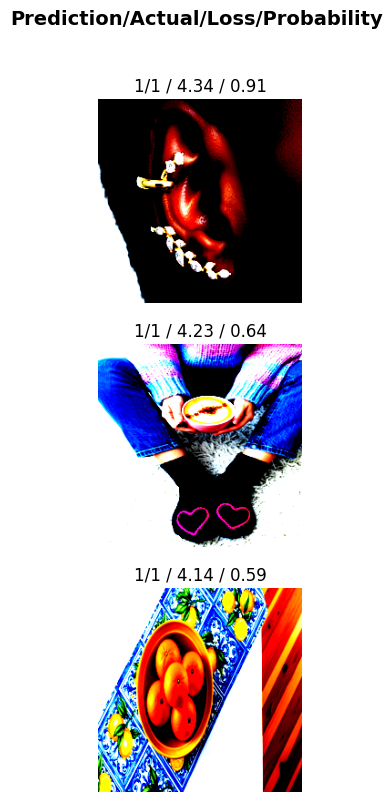

              precision    recall  f1-score   support

           0       0.75      0.74      0.75       496
           1       0.73      0.73      0.73       464

    accuracy                           0.74       960
   macro avg       0.74      0.74      0.74       960
weighted avg       0.74      0.74      0.74       960


FINAL PERFORMANCE METRICS
Technique Architecture  Test Loss  Test Accuracy (%)  Precision  Recall  F1 Score  Support
 Baseline    Basic_CNN     0.5689              73.75     0.7375  0.7375    0.7375      960


In [117]:
# Define techniques and models
techniques = ["Baseline"]
models = ["Basic_CNN"]

# Initialize empty results list
results_list = []

# Iterate over data techniques
for tech in techniques:

    # Match dataloader to technique
    match tech:
        case "Baseline":
            test_dl = baseline_test_dl

    # Iterate through model architectures
    for mod in models:

        # Define exact model path
        model_path = f"models/{tech}/{mod}.pkl"

        # Check if file exists
        if os.path.isfile(model_path):

            # Load saved learner file
            learner = load_learner(model_path)

            # Print current analysis header
            print(f"\n{'='*60}")
            print(f"Analyzing: Architecture = {mod} | Technique = {tech}")
            print(f"{'='*60}")

            # Create interpretation from learner
            interp = ClassificationInterpretation.from_learner(learner, dl=test_dl)

            # Plot top three losses
            interp.plot_top_losses(3, nrows=3)

            # Show plot before continuing
            plt.show()

            # Print text classification report
            interp.print_classification_report()

            # Get predictions and targets
            preds, targs = learner.get_preds(dl=test_dl)

            # Convert probabilities to classes
            preds = preds.argmax(dim=1)

            # Generate dictionary metrics report
            report = classification_report(targs, preds, output_dict=True, zero_division=0)

            # Extract weighted average metrics
            avg_prec = report['weighted avg']['precision']
            avg_rec = report['weighted avg']['recall']
            avg_f1 = report['weighted avg']['f1-score']
            avg_supp = report['weighted avg']['support']

            # Validate on test set
            metrics = learner.validate(dl=test_dl)

            # Extract loss and accuracy
            test_loss = metrics[0]
            test_acc = metrics[1]

            # Append metrics to results
            results_list.append({
                "Technique": tech,
                "Architecture": mod,
                "Test Loss": round(test_loss, 4),
                "Test Accuracy (%)": round(test_acc * 100, 2),
                "Precision": round(avg_prec, 4),
                "Recall": round(avg_rec, 4),
                "F1 Score": round(avg_f1, 4),
                "Support": int(avg_supp)
            })

        else:
            # Append missing model placeholders
            results_list.append({
                "Technique": tech,
                "Architecture": mod,
                "Test Loss": None,
                "Test Accuracy (%)": None,
                "Precision": None,
                "Recall": None,
                "F1 Score": None,
                "Support": None
            })

# Convert results to dataframe
results_df = pd.DataFrame(results_list)

# Print final performance table
print(f"\n{'='*60}")
print("FINAL PERFORMANCE METRICS")
print(f"{'='*60}")
print(results_df.to_string(index=False))

In [118]:
results_df.sort_values(by=['Test Accuracy (%)'], ascending=False)

,Technique,Architecture,Test Loss,Test Accuracy (%),Precision,Recall,F1 Score,Support
0,Baseline,Basic_CNN,0.5689,73.75,0.7375,0.7375,0.7375,960


### Best and Worst

In [119]:
# Remove any rows where models weren't trained (None values)
clean_results = results_df.dropna(subset=['F1 Score'])

# Get the single best and single worst
best_row = clean_results.sort_values(by='F1 Score', ascending=False).head(1)
worst_row = clean_results.sort_values(by='F1 Score', ascending=True).head(1)

# Combine them into a single 2-row dataframe
best_vs_worst = pd.concat([best_row, worst_row])

print("--- Performance Extremes: Best vs. Worst Model ---")
display(best_vs_worst)

--- Performance Extremes: Best vs. Worst Model ---


,Technique,Architecture,Test Loss,Test Accuracy (%),Precision,Recall,F1 Score,Support
0,Baseline,Basic_CNN,0.5689,73.75,0.7375,0.7375,0.7375,960
0,Baseline,Basic_CNN,0.5689,73.75,0.7375,0.7375,0.7375,960


# 8. Submission

## Create test.csv

In [122]:
# Setup paths for script
submission_folder = os.path.join(other_dir, "Submission")
model_path = "./models/Baseline/Basic_CNN.pkl"

print("Loading model...")
# Load the trained model
learn = load_learner(model_path)

# Safely get all image paths
test_images = get_image_files(submission_folder)

print(f"Found {len(test_images)} images. Running predictions...")

print(learn.dls.vocab)

# Create a test data loader
test_dl = learn.dls.test_dl(test_images)

# Run predictions and get classes
preds, _, decoded = learn.get_preds(dl=test_dl, with_decoded=True)

# Extract filenames from image paths
image_ids = [img.name for img in test_images]
# Convert tensor to numpy array
predicted_classes = decoded.numpy() 

# Build dataframe and export CSV
submission_df = pd.DataFrame({
    "image_id": image_ids,
    "ground_truth": predicted_classes
})

os.makedirs(os.path.join("final_submission"), exist_ok=True)

submission_csv_path = os.path.join("final_submission", "submission.csv")
submission_df.to_csv(submission_csv_path, index=False)

print(f"Done! Saved submission to: {submission_csv_path}")

Loading model...
Found 2058 images. Running predictions...
['0', '1']


c:\Users\Danie\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\fastai\learner.py:455: UserWarning:

load_learner` uses Python's insecure pickle module, which can execute malicious arbitrary code when loading. Only load files you trust.
If you only need to load model weights and optimizer state, use the safe `Learner.load` instead.



Done! Saved submission to: final_submission\submission.csv


## Compare disagreements with teammate

In [123]:
# Load both CSV files
my_sub = pd.read_csv("./final_submission/submission.csv")
team_sub = pd.read_csv("../../submission.csv")

# Merge them together
comparison = pd.merge(my_sub, team_sub, on="image_id", suffixes=('_mine', '_team'))

# Filter for rows where the predictions do not match
disagreements = comparison[comparison['ground_truth'] != comparison['prediction']]

# Print out the summary
print(f"Total images compared: {len(comparison)}")
print(f"Total disagreements: {len(disagreements)}")
print(f"Agreement rate: {100 - (len(disagreements) / len(comparison) * 100):.2f}%\n")

# Look at the first few mismatched files
print("First 5 disagreements:")
display(disagreements.head())

# Save to new csv
disagreements.to_csv("disagreements_to_review.csv", index=False)

Total images compared: 2058
Total disagreements: 1109
Agreement rate: 46.11%

First 5 disagreements:


,image_id,ground_truth,prediction
1,000a811d-cf8f-4b5b-be75-bd9f1a73c098.jpg,1,0
3,00888016-16c4-4ce7-a03e-073f04a1a9c8.jpg,1,0
8,016c8689-9c23-49a2-b918-4616cc98ae80.jpg,1,0
14,02ad5821-08e8-463f-8575-7136f2c88221.jpg,1,0
15,02ade214-f576-4867-8c55-62bccdc182a6.jpg,1,0
